# Buổi F5: t-SNE, vẽ bản đồ 2D giữ hàng xóm ở gần nhau

**Hiện trường.** PCA ở F4 cho ảnh chữ số một bức tranh 2D, nhưng các chữ số chồng lên nhau khá nhiều. Chị Hạnh muốn một tấm bản đồ rõ hơn, để **nhìn bằng mắt** xem dữ liệu có tự chia thành mảng hay không trước khi làm gì tiếp.

Buổi này dạy **t-SNE**: thay vì tìm hướng trải dài nhất, nó tìm cách đặt từng điểm lên mặt phẳng sao cho **những điểm vốn là hàng xóm thì vẫn là hàng xóm**.

**Ẩn dụ:** bạn có danh sách 1.000 người và biết ai thân với ai. Hãy xếp họ vào một sân 2D sao cho bạn thân đứng gần nhau, người lạ đứng xa. Sân không có chỗ cho mọi thứ đúng tuyệt đối, nên vẫn có người đứng chưa hợp; nhưng **nhóm bạn thân** thường vẫn tụ lại.

**Mindset của người làm dữ liệu:** t-SNE là **công cụ nhìn**, không phải công cụ đo. Khoảng cách giữa các mảng và kích thước mảng trên hình **không có nghĩa** đo lường. Hình chỉ gợi ý chỗ để kiểm tra tiếp.

**Lưu ý:** dùng `digits` (1.000 ảnh đầu để chạy nhanh) và `make_swiss_roll`; dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: PCA và t-SNE trên cùng ảnh chữ số |
| Chặng 1 | Đo thay vì tin mắt: giữ lại được bao nhiêu hàng xóm |
| Chặng 2 | Núm perplexity |
| Chặng 3 | Bẫy: khoảng cách giữa các mảng và hình mỗi lần một khác |
| Chặng 4 | Dùng đúng: để nhìn, không để gom nhóm |
| Chặng 5 | Dữ liệu cuộn: cuộn bánh Thụy Sĩ |

## Chặng 0: Thấy ngay, PCA và t-SNE

**Câu hỏi:** cùng 1.000 ảnh chữ số, hai tấm bản đồ khác nhau thế nào?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

t-SNE seconds: 4.2


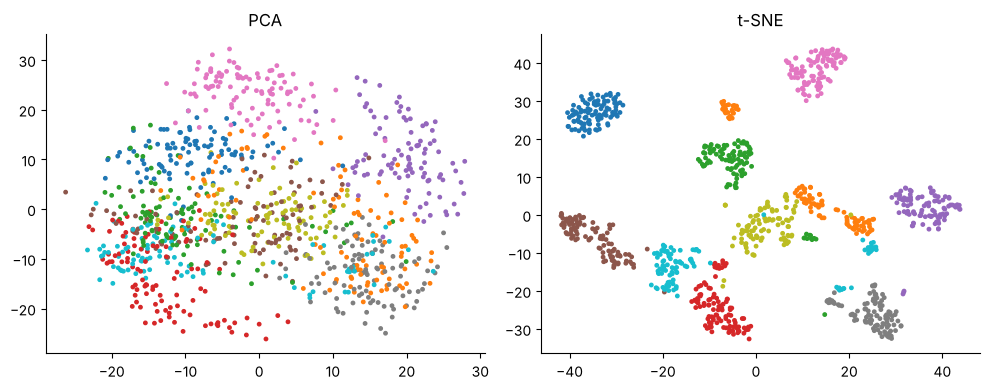

In [2]:
import time
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
digits = load_digits()
X, y = digits.data[:1000], digits.target[:1000]
Zp = PCA(n_components=2).fit_transform(X)
t0 = time.time()
Zt = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(X)
t_tsne = round(time.time() - t0, 1)
print("t-SNE seconds:", t_tsne)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(*Zp.T, c=y, cmap="tab10", s=6); ax[0].set_title("PCA")
ax[1].scatter(*Zt.T, c=y, cmap="tab10", s=6); ax[1].set_title("t-SNE")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `digits.data[:1000]`: lấy 1.000 ảnh đầu cho chạy nhanh (t-SNE chậm hơn PCA nhiều).
- `TSNE(n_components=2, perplexity=30, init="pca", random_state=0)`: `perplexity` ≈ số hàng xóm mỗi điểm "quan tâm" (chặng 2). `init="pca"` khởi đầu từ bản đồ PCA cho ổn định hơn.
- `.fit_transform(X)`: t-SNE **không có** `transform` cho dữ liệu mới: nó chỉ vẽ lại đúng bộ điểm đã đưa vào.
- `c=y`: tô màu theo chữ số thật **chỉ để ta nhìn**; cả PCA và t-SNE không dùng nhãn.

**Cách đọc.**
- **Con số:** t-SNE chạy 1.000 ảnh mất **3,7** giây; PCA gần như tức thì.
- **Bức tranh:** PCA cho đám mây chồng lên nhau; t-SNE tách các chữ số thành các mảng riêng rõ hơn hẳn.
- **Câu hỏi tiếp:** mắt thấy rõ hơn, nhưng "rõ hơn" có đo được không?

**Mang về chặng 1:** t-SNE đặt điểm lên 2D sao cho hàng xóm vẫn ở gần nhau.

## Chặng 1: Đo thay vì tin mắt

**Câu hỏi:** bao nhiêu hàng xóm thật của mỗi ảnh vẫn là hàng xóm trên bản đồ 2D?

In [3]:
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import trustworthiness
def neighbor_overlap(high, low, k=10):
    a = NearestNeighbors(n_neighbors=k + 1).fit(high).kneighbors(high, return_distance=False)[:, 1:]
    b = NearestNeighbors(n_neighbors=k + 1).fit(low).kneighbors(low, return_distance=False)[:, 1:]
    return float(np.mean([len(set(a[i]) & set(b[i])) / k for i in range(len(high))]))
score = pd.DataFrame({
    "neighbors kept (of 10)": [neighbor_overlap(X, Zp), neighbor_overlap(X, Zt)],
    "trustworthiness": [trustworthiness(X, Zp, n_neighbors=10), trustworthiness(X, Zt, n_neighbors=10)],
}, index=["PCA", "t-SNE"]).round(3)
print(score.to_string())

       neighbors kept (of 10)  trustworthiness
PCA                     0.166            0.801
t-SNE                   0.662            0.993


**Giải thích từng dòng**

- `NearestNeighbors(n_neighbors=k + 1)`: tìm k hàng xóm gần nhất (cộng thêm 1 vì điểm gần nhất luôn là chính nó).
- `.kneighbors(high, ...)[:, 1:]`: danh sách hàng xóm trong không gian **64 cột** (bỏ chính nó).
- `set(a[i]) & set(b[i])`: giao của hai danh sách: bao nhiêu người vừa là hàng xóm thật vừa là hàng xóm trên bản đồ 2D.
- `trustworthiness(X, Z, n_neighbors=10)`: thước có sẵn của sklearn, từ 0 đến 1: các điểm đứng gần nhau trên bản đồ có thật sự gần nhau ban đầu không. Gần 1 là tốt.

**Cách đọc.**
- **Con số:** PCA giữ **16,6%** hàng xóm, t-SNE giữ **66,2%**. Độ tin cậy (trustworthiness): PCA **0,801**, t-SNE **0,993**.
- **Bức tranh:** t-SNE giữ hàng xóm tốt hơn nhiều vì đó là thứ nó được thiết kế để tối ưu. Nhưng cả hai đều không giữ trọn: nén 64 chiều xuống 2 chiều không thể giữ hết.
- **Quy tắc đọc:** hình đẹp chưa phải bằng chứng; con số giữ hàng xóm mới là thước.
- **Câu hỏi tiếp:** t-SNE có núm vặn nào ảnh hưởng hình?

**Mang về chặng 2:** đo bằng tỷ lệ hàng xóm giữ lại và trustworthiness.

## Chặng 2: Núm perplexity

**Câu hỏi:** "bao nhiêu hàng xóm mỗi điểm quan tâm" đổi thì hình đổi thế nào?

            neighbors kept  trustworthiness  seconds
perplexity                                          
5                    0.613            0.990      3.2
30                   0.662            0.993      3.9
100                  0.626            0.989      6.1


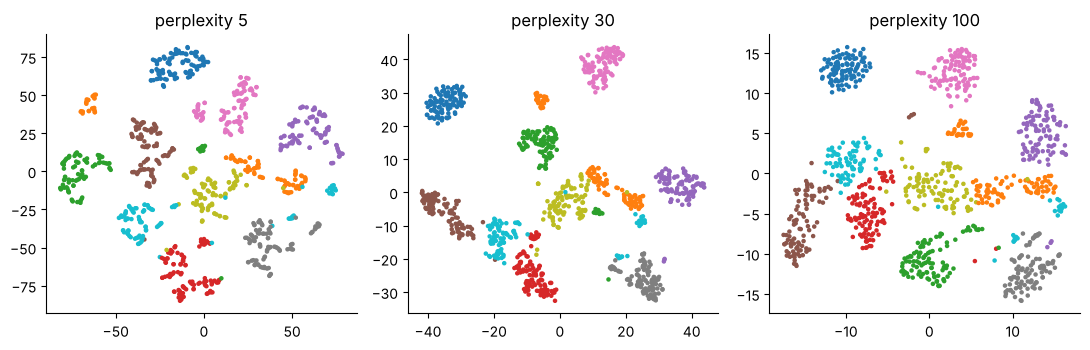

In [4]:
rows, maps = [], {}
for pp in [5, 30, 100]:
    t0 = time.time()
    Z = TSNE(n_components=2, perplexity=pp, init="pca", random_state=0).fit_transform(X)
    maps[pp] = Z
    rows.append({"perplexity": pp, "neighbors kept": round(neighbor_overlap(X, Z), 3), "trustworthiness": round(trustworthiness(X, Z, n_neighbors=10), 3), "seconds": round(time.time() - t0, 1)})
pp_table = pd.DataFrame(rows).set_index("perplexity")
print(pp_table.to_string())
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for a, pp in zip(ax, maps):
    a.scatter(*maps[pp].T, c=y, cmap="tab10", s=5); a.set_title(f"perplexity {pp}")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `for pp in [5, 30, 100]`: ba mức: ít hàng xóm (5), vừa (30), nhiều (100).
- `maps[pp] = Z`: giữ lại từng bản đồ để vẽ cạnh nhau.

**Cách đọc.**
- **Con số:** tỷ lệ hàng xóm giữ lại: perplexity 5 → **61,3%**, 30 → **66,2%**, 100 → **62,6%**.
- **Bức tranh:** perplexity nhỏ chú ý cấu trúc rất cục bộ, hay vỡ mảng thành nhiều đảo nhỏ; lớn thì nhìn rộng hơn, mảng lớn gọn hơn nhưng chi tiết mịn mờ dần. Không có giá trị "đúng", nên thử vài mức, thường 5 đến 50.
- **Quy tắc đọc:** nếu một kết luận chỉ đúng ở một perplexity thì đừng tin kết luận đó.
- **Câu hỏi tiếp:** hình đã đẹp rồi, đọc khoảng cách trên hình thế nào cho đúng?

**Mang về chặng 3:** perplexity đổi cách nhìn; thử một dải.

## Chặng 3: Bẫy, khoảng cách trên hình và hình mỗi lần một khác

**Câu hỏi:** hai mảng đứng xa nhau trên bản đồ có thật sự khác nhau nhiều hơn hai mảng đứng gần?

In [5]:
cents_hi = np.array([X[y == d].mean(axis=0) for d in range(10)])
d_hi = np.linalg.norm(cents_hi[:, None] - cents_hi[None], axis=2)[np.triu_indices(10, 1)]
runs = {}
for seed in [0, 1, 2]:
    Zs = TSNE(n_components=2, perplexity=30, init="random", random_state=seed).fit_transform(X)
    c = np.array([Zs[y == d].mean(axis=0) for d in range(10)])
    runs[seed] = np.linalg.norm(c[:, None] - c[None], axis=2)[np.triu_indices(10, 1)]
corr = pd.DataFrame({f"seed {s}": [np.corrcoef(d_hi, runs[s])[0, 1]] + [np.corrcoef(runs[s], runs[t])[0, 1] if t != s else 1.0 for t in runs] for s in runs}, index=["true 64-D", "seed 0", "seed 1", "seed 2"]).round(2)
print("correlation between centroid distances (45 digit pairs):")
print(corr.to_string())

correlation between centroid distances (45 digit pairs):
           seed 0  seed 1  seed 2
true 64-D    0.77    0.65    0.78
seed 0       1.00    0.72    0.98
seed 1       0.72    1.00    0.76
seed 2       0.98    0.76    1.00


**Giải thích từng dòng**

- `X[y == d].mean(axis=0)`: tâm của từng chữ số trong không gian 64 cột.
- `np.triu_indices(10, 1)`: lấy 45 cặp chữ số khác nhau.
- `init="random", random_state=seed`: khởi đầu ngẫu nhiên với ba hạt giống: ba bản đồ khác nhau của cùng dữ liệu.
- `np.corrcoef(a, b)[0, 1]`: hệ số tương quan giữa hai danh sách 45 khoảng cách: 1 là khoảng cách trên hình khớp hoàn toàn với khoảng cách thật.

**Cách đọc.**
- **Con số:** tương quan giữa khoảng cách tâm các chữ số trên mỗi bản đồ và khoảng cách thật ở 64 chiều: **0,77, 0,65, 0,78** (ba hạt giống). Giữa các bản đồ với nhau: **0,72**, **0,98**, **0,76**.
- **Bức tranh:** các số này nằm ở mức vừa phải, không gần 1: khoảng cách trên hình chỉ **gợi ý mờ** về khoảng cách thật, và hai lần chạy khác hạt giống có thể cho cách xếp mảng khác nhau (có cặp hạt giống khớp nhau gần hoàn toàn, có cặp lệch rõ). t-SNE chỉ cam kết "hàng xóm gần vẫn gần", không cam kết mảng nào xa mảng nào, hay mảng to hay nhỏ.
- **Quy tắc đọc:** dùng để thấy **có mảng hay không**, không dùng để nói "chữ số 3 giống 5 hơn giống 8" từ khoảng cách trên hình.
- **Câu hỏi tiếp:** vậy dùng toạ độ t-SNE để gom nhóm được không?

**Mang về chặng 4:** khoảng cách giữa mảng và kích thước mảng trên t-SNE không có nghĩa đo lường.

## Chặng 4: Dùng đúng, để nhìn, không để gom nhóm

**Câu hỏi:** gom nhóm trên toạ độ 2D của t-SNE có tốt hơn gom nhóm trên dữ liệu gốc không?

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
km_orig = KMeans(10, n_init=10, random_state=0).fit_predict(X)
km_tsne = KMeans(10, n_init=10, random_state=0).fit_predict(Zt)
km_pca = KMeans(10, n_init=10, random_state=0).fit_predict(PCA(n_components=20).fit_transform(X))
print("K-Means(10) ARI vs the real digits:")
print("  on 64 original columns :", round(adjusted_rand_score(y, km_orig), 3))
print("  on 20 PCA directions   :", round(adjusted_rand_score(y, km_pca), 3))
print("  on the 2-D t-SNE map   :", round(adjusted_rand_score(y, km_tsne), 3))
t0 = time.time()
Zt2 = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(PCA(n_components=30).fit_transform(X))
t_pre = round(time.time() - t0, 1)
from sklearn.metrics import silhouette_score
noise = np.random.RandomState(0).randn(1000, 64)
noise_map = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(noise)
sil_noise_high = silhouette_score(noise, KMeans(10, n_init=10, random_state=0).fit_predict(noise))
sil_noise_map = silhouette_score(noise_map, KMeans(10, n_init=10, random_state=0).fit_predict(noise_map))
print("pure random noise, K-Means(10) silhouette: original space", round(sil_noise_high, 3), "| t-SNE map", round(sil_noise_map, 3))
print("t-SNE after PCA(30): seconds", t_pre, "| neighbors kept:", round(neighbor_overlap(X, Zt2), 3), "vs direct:", round(neighbor_overlap(X, Zt), 3))

K-Means(10) ARI vs the real digits:
  on 64 original columns : 0.647
  on 20 PCA directions   : 0.641
  on the 2-D t-SNE map   : 0.78


pure random noise, K-Means(10) silhouette: original space 0.012 | t-SNE map 0.323
t-SNE after PCA(30): seconds 4.0 | neighbors kept: 0.663 vs direct: 0.662


**Giải thích từng dòng**

- `KMeans(10, ...)`: gom 10 nhóm (ta biết có 10 chữ số) ở ba không gian khác nhau.
- `PCA(n_components=20).fit_transform(X)`: không gian PCA 20 chiều (F4): đã nén nhưng còn giữ gần hết thông tin.
- `np.random.RandomState(0).randn(1000, 64)`: 1000 điểm **hoàn toàn ngẫu nhiên** trong 64 chiều: không có nhóm nào cả. Dùng để thử t-SNE có "bịa" ra nhóm không.
- `silhouette_score(noise_map, ...)`: độ gọn của các nhóm tìm được (F1): cao nghĩa là nhóm nhìn rất rõ.
- `TSNE(...).fit_transform(PCA(n_components=30)...)`: cách làm thường dùng với dữ liệu nhiều cột: **nén bằng PCA trước** rồi mới t-SNE, vừa nhanh vừa đỡ nhiễu.

**Cách đọc.**
- **Con số:** ARI của K-Means: dữ liệu gốc **0,647**, PCA 20 chiều **0,641**, bản đồ t-SNE **0,780**. Chạy t-SNE sau PCA(30) mất **4,1** giây, giữ **66,3%** hàng xóm (chạy thẳng: **66,2%**).
- **Bức tranh:** trên bản đồ t-SNE, K-Means chấm cao hơn (**0,780** so với **0,647**) vì t-SNE đã gom các hàng xóm lại thành mảng gọn sẵn. Nhưng chính đặc điểm đó là cái bẫy: với 1.000 điểm **ngẫu nhiên, không có nhóm nào**, độ gọn của nhóm (silhouette) là **0,012** ở không gian gốc nhưng **0,323** trên bản đồ t-SNE. Bản đồ t-SNE có thể làm nhiễu trông như có nhóm.
- **Quy tắc đọc:** quy trình tốt: gom nhóm ở không gian gốc hoặc sau PCA, rồi **tô màu nhóm lên bản đồ t-SNE để kiểm tra bằng mắt**. t-SNE là cửa sổ để nhìn, không phải công cụ để gom.
- **Lưu ý:** t-SNE không có `transform` cho khách mới. Cần chiếu dữ liệu mới thì dùng PCA.

**Mang về chặng 5:** nhìn bằng t-SNE, xác nhận nhóm bằng dữ liệu gốc.

## Chặng 5: Dữ liệu cuộn, cuộn bánh Thụy Sĩ

**Câu hỏi:** khi dữ liệu nằm trên một mặt cong cuộn lại, PCA và t-SNE làm gì?

                           PCA  Isomap  t-SNE
neighbors kept (of 10)   0.544   0.879  0.867
trustworthiness          0.954   1.000  1.000
corr with true position  0.219   0.992  0.131


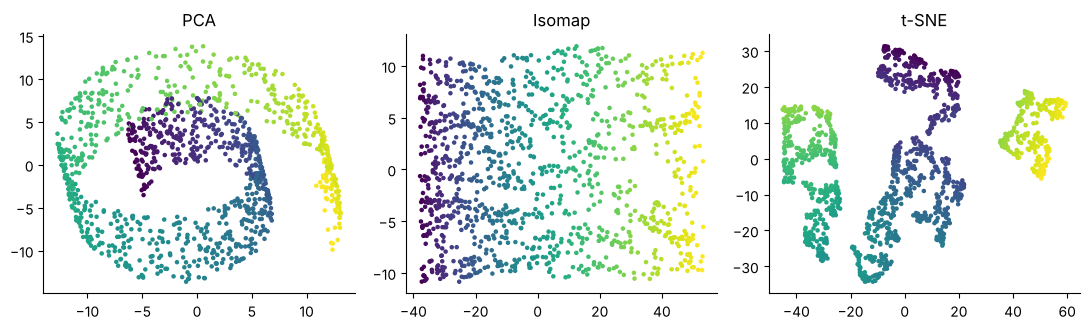

In [7]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import Isomap
roll, pos = make_swiss_roll(1200, noise=0.05, random_state=0)
maps3 = {
    "PCA": PCA(n_components=2).fit_transform(roll),
    "Isomap": Isomap(n_neighbors=12, n_components=2).fit_transform(roll),
    "t-SNE": TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(roll),
}
roll_score = pd.DataFrame({name: {"neighbors kept (of 10)": neighbor_overlap(roll, Z), "trustworthiness": trustworthiness(roll, Z, n_neighbors=10), "corr with true position": abs(np.corrcoef(Z[:, 0], pos)[0, 1])} for name, Z in maps3.items()}).round(3)
print(roll_score.to_string())
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
for a, (name, Z) in zip(ax, maps3.items()):
    a.scatter(*Z.T, c=pos, cmap="viridis", s=5); a.set_title(name)
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `make_swiss_roll(1200, noise=0.05)`: dải giấy 2D cuộn thành cuộn bánh trong không gian 3D (dữ liệu dựng có chủ đích). `pos` là vị trí dọc theo dải giấy khi trải phẳng.
- `Isomap(n_neighbors=12, n_components=2)`: cách khác: đo khoảng cách **đi dọc mặt cong** (qua các hàng xóm) thay vì đường chim bay, rồi mở phẳng ra.
- `abs(np.corrcoef(Z[:, 0], pos)[0, 1])`: trục ngang của bản đồ có bám theo vị trí thật dọc dải giấy không.

**Cách đọc.**
- **Con số:** hàng xóm giữ lại: PCA **54,4%**, Isomap **87,9%**, t-SNE **86,7%**. Tương quan trục ngang với vị trí thật: PCA **0,22**, Isomap **0,99**, t-SNE **0,13**.
- **Bức tranh:** PCA chỉ có phép chiếu thẳng nên nhìn cuộn bánh từ một phía: các lớp giấy cuộn thành vòng xoắn và đè lên nhau. Isomap mở phẳng được dải giấy, thứ tự màu chạy đều từ trái sang phải (tương quan với vị trí thật gần 1). t-SNE giữ hàng xóm gần như Isomap nhưng **xé dải thành nhiều mảnh rời**, và các mảnh xếp không theo thứ tự thật (trục của bản đồ không mang ý nghĩa, đúng như chặng 3).
- **Quy tắc đọc:** dữ liệu thật hiếm khi cuộn đẹp như cuộn bánh; vẫn nên thử PCA trước vì nhanh, giải thích được, có `transform`. Khi PCA cho hình chồng chéo, t-SNE hoặc Isomap là bước nhìn thứ hai.

**Mang về:** PCA để nén và giải thích; t-SNE để nhìn; đo hàng xóm giữ lại trước khi tin hình.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | t-SNE đặt điểm lên 2D sao cho hàng xóm vẫn gần nhau; tách mảng rõ hơn PCA. |
| 1 | Đo bằng tỷ lệ hàng xóm giữ lại và trustworthiness, không chỉ bằng mắt. |
| 2 | Perplexity đổi cách nhìn; thử một dải 5 đến 50. |
| 3 | Khoảng cách giữa mảng và kích thước mảng không có nghĩa; mỗi lần chạy một khác. |
| 4 | Gom nhóm ở dữ liệu gốc, dùng t-SNE để nhìn kiểm tra. |
| 5 | Dữ liệu cuộn: t-SNE, Isomap mở được, PCA thì không. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Xếp bạn thân đứng gần nhau trong sân | t-SNE | `TSNE` |
| Bao nhiêu bạn thân mỗi người để ý | perplexity | `perplexity` |
| Bao nhiêu hàng xóm thật còn gần trên bản đồ | độ tin cậy lân cận | `trustworthiness` |
| Đo đường đi dọc mặt cong | Isomap | `Isomap` |
| Khởi đầu từ bản đồ PCA | khởi tạo PCA | `init="pca"` |
| Nén trước khi vẽ cho nhanh | PCA rồi t-SNE | `PCA(30)` → `TSNE` |

**Thử thách tự làm**

1. Ở chặng 2, thử perplexity 2 và 300. Hình thế nào? Giữ được bao nhiêu hàng xóm?
2. Ở chặng 4, chạy t-SNE trên cả 1797 ảnh. Thời gian tăng bao nhiêu so với 1.000 ảnh?
3. Ở chặng 5, thêm `noise=1.0` vào cuộn bánh. Isomap còn mở được không?
4. Dùng t-SNE trên dữ liệu `wine` (F4) sau khi chuẩn hóa. Ba loại rượu có tách mảng không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Phân biệt vai trò PCA và t-SNE.
- [ ] Đo được độ giữ hàng xóm của một bản đồ 2D.
- [ ] Biết thử nhiều perplexity.
- [ ] Không diễn giải khoảng cách giữa các mảng trên hình t-SNE.
- [ ] Gom nhóm ở dữ liệu gốc, dùng t-SNE để nhìn.

## Phần thưởng (Tip pro): UMAP, người anh em nhanh hơn


UMAP làm việc tương tự t-SNE nhưng nhanh hơn, giữ cấu trúc toàn cục tốt hơn một chút và có `transform` cho dữ liệu mới. Nó là thư viện riêng (`umap-learn`) nên ta không dùng trong khóa này (chỉ dùng sklearn); cách đọc hình thì giống: là cửa sổ để nhìn, không phải thước đo.